# SwiftBasket: which growth is worth having?
Straive case study #1 · Aritra Pal, PGPM 2027, Great Lakes Institute of Management, Chennai

The COO's question was simple: growth is easy to buy, so which growth is worth having?

My short answer is that SwiftBasket doesn't have a growth problem. It has a leak problem. An average order earns about ₹167 in product margin and fees, and discounts plus refunds take ₹66 of it, which is more than the ₹44 we keep. Stock-outs are behind most refunds. The 20-minute delivery promise is shown regardless of distance and is late 40% of the time. And the Q1 promo lost ₹12.5 of margin per customer because most of it went to people who were going to order anyway.

| Case ask | Section |
|---|---|
| 1. Business health | §2 |
| 2. Profitable repeat behaviour | §3 |
| 3. Operational priorities | §4 |
| 4. Promotion strategy (randomized campaign) | §5 |
| 5. Three actions for next quarter | §6 |

How it's built: the core metrics are SQL queries (DuckDB) over the four sheets. Python handles the bootstrap confidence intervals, a holdout check and the charts. The same queries are saved in `sql/analysis_queries.sql`.

Where I used AI: Claude (an AI assistant) helped with the code, charts and write-up drafts. I reviewed each step and I'm responsible for the numbers. To check them I re-computed the headline figures in plain pandas, separately from the SQL (§7), and confirmed the contribution-margin formula reconciles to the rupee on every order.

## 0 · Setup

In [1]:
import glob, os, warnings
try:
    import duckdb
except ImportError:  # e.g. a fresh Kaggle kernel
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "duckdb"])
    import duckdb
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# Works locally (data/ folder) and on Kaggle (/kaggle/input/<your-dataset>/)
CANDIDATES = ["../data/SwiftBasket_2026_Case_Data.xlsx", "data/SwiftBasket_2026_Case_Data.xlsx"] + \
             glob.glob("/kaggle/input/**/*SwiftBasket*Case_Data*.xlsx", recursive=True)
PATH = next(p for p in CANDIDATES if os.path.exists(p))
CHARTS = "../charts" if os.path.isdir("../charts") else "charts"
os.makedirs(CHARTS, exist_ok=True)
print("Data:", PATH)

sheets = {s: pd.read_excel(PATH, sheet_name=s) for s in ["orders", "customers", "stores", "campaign_assignments"]}
con = duckdb.connect()
for name, df in sheets.items():
    con.register(name, df)
q = lambda sql: con.sql(sql).df()
{k: v.shape for k, v in sheets.items()}

Data: ../data/SwiftBasket_2026_Case_Data.xlsx


{'orders': (30000, 25),
 'customers': (8000, 14),
 'stores': (36, 10),
 'campaign_assignments': (8000, 9)}

In [2]:
# Chart style: one recessive look for every chart (validated categorical palette)
BLUE, ORANGE, AQUA, YELLOW, RED, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#d03b3b", "#c3c2b7", "#0b0b0b", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.family": "DejaVu Sans", "font.size": 11, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
})
def save(fig, name):
    fig.savefig(f"{CHARTS}/{name}.png", dpi=200, bbox_inches="tight"); plt.show()
def rupee(x, d=0): return f"₹{x:,.{d}f}"

## 1 · Getting to know the data
Before looking for insights I checked three things: the grain of each table, whether the joins hold, and which fields are only known after the fact.

In [3]:
# Row counts, date window and join integrity
qa = q("""
SELECT
  (SELECT COUNT(*) FROM orders)                                   AS orders,
  (SELECT COUNT(DISTINCT customer_id) FROM orders)                AS ordering_customers,
  (SELECT COUNT(*) FROM customers)                                AS customers,
  (SELECT COUNT(*) FROM stores)                                   AS stores,
  (SELECT MIN(order_timestamp) FROM orders)                       AS first_order,
  (SELECT MAX(order_timestamp) FROM orders)                       AS last_order,
  (SELECT COUNT(*) FROM orders o LEFT JOIN customers c USING (customer_id) WHERE c.customer_id IS NULL) AS orphan_customer_rows,
  (SELECT COUNT(*) FROM orders o LEFT JOIN stores s USING (store_id) WHERE s.store_id IS NULL)          AS orphan_store_rows,
  (SELECT SUM(ABS(gross_margin_inr + delivery_fee_inr - discount_inr - picking_cost_inr
                  - delivery_cost_inr - refund_inr - contribution_margin_inr)) FROM orders)              AS cm_identity_error_inr
""")
qa

,orders,ordering_customers,customers,stores,first_order,last_order,orphan_customer_rows,orphan_store_rows,cm_identity_error_inr
0,30000,6759,8000,36,2025-01-01 08:19:00,2025-12-31 23:30:00,0,0,2.478780e-10


Joins are clean, and the contribution-margin formula in the Data Dictionary matches the column on all 30,000 orders.

Next, a leakage check. The Data Dictionary says `historical_orders_12m` and `historical_margin_12m` are known at decision time. Do they overlap the outcome window?

In [4]:
# Are the customer 'history' fields just the 2025 order table re-aggregated?
leak = q("""
WITH agg AS (SELECT customer_id, COUNT(*) n, SUM(contribution_margin_inr) cm FROM orders GROUP BY 1)
SELECT
  AVG(CASE WHEN c.historical_orders_12m = COALESCE(a.n,0) THEN 1 ELSE 0 END)            AS share_orders_match,
  CORR(c.historical_margin_12m, COALESCE(a.cm,0))                                        AS corr_margin
FROM customers c LEFT JOIN agg a USING (customer_id)
""")
leak

,share_orders_match,corr_margin
0,1.0,1.0


They do. Both fields are just the 2025 order table re-aggregated. That's fine for targeting the Q1 2026 campaign, because by then they really are history. It would be circular to use them to explain `repeat_order_30d`, which sits inside the same 2025 window. So §3 only uses them descriptively, and the targeting rule in §5 uses recency and app sessions, which exist before the campaign starts.

One more caveat. 30,000 orders across 36 stores is about 2.3 orders per store per day, so this is a sample, not the full business. I report impact per order, per customer and as a share of contribution margin rather than as company-wide rupee totals.

## 2 · Business health (Ask 1)

In [5]:
# Headline KPI scorecard (2025)
kpi = q("""
SELECT
  COUNT(*)                                                     AS orders,
  SUM(basket_value_inr)                                        AS gmv_inr,
  AVG(basket_value_inr)                                        AS aov_inr,
  SUM(contribution_margin_inr)                                 AS contribution_margin_inr,
  SUM(contribution_margin_inr) / SUM(basket_value_inr)         AS cm_pct_gmv,
  AVG(contribution_margin_inr)                                 AS cm_per_order,
  AVG(CASE WHEN contribution_margin_inr < 0 THEN 1 ELSE 0 END) AS loss_making_order_share,
  SUM(discount_inr) / SUM(basket_value_inr)                    AS discount_pct_gmv,
  SUM(refund_inr)   / SUM(basket_value_inr)                    AS refund_pct_gmv,
  AVG(late_delivery_flag)                                      AS late_rate,
  AVG(CASE WHEN stockout_item_count > 0 THEN 1 ELSE 0 END)     AS orders_with_stockout,
  AVG(cancelled_flag)                                          AS cancel_rate,
  AVG(service_contact_flag)                                    AS support_contact_rate,
  AVG(rating)                                                  AS avg_rating
FROM orders
""")
kpi

,orders,gmv_inr,aov_inr,contribution_margin_inr,cm_pct_gmv,cm_per_order,loss_making_order_share,discount_pct_gmv,refund_pct_gmv,late_rate,orders_with_stockout,cancel_rate,support_contact_rate,avg_rating
0,30000,16791762.15,559.725405,1328227.61,0.0791,44.274254,0.209967,0.080014,0.0381,0.172756,0.6395,0.010167,0.127167,4.208278


In [6]:
kpi.T.rename(columns={0: 'value'}).style.format('{:,.3f}')

,value
orders,"30,000.000"
gmv_inr,"16,791,762.150"
aov_inr,559.725
contribution_margin_inr,"1,328,227.610"
cm_pct_gmv,0.079
cm_per_order,44.274
loss_making_order_share,0.210
discount_pct_gmv,0.080
refund_pct_gmv,0.038
late_rate,0.173


In [7]:
# Unit economics: where does an average order's ₹ go?
unit = q("""
SELECT AVG(gross_margin_inr) AS gross_margin, AVG(delivery_fee_inr) AS delivery_fee,
       -AVG(discount_inr) AS discount, -AVG(picking_cost_inr) AS picking,
       -AVG(delivery_cost_inr) AS last_mile, -AVG(refund_inr) AS refunds,
       AVG(contribution_margin_inr) AS contribution_margin
FROM orders
""")
unit

,gross_margin,delivery_fee,discount,picking,last_mile,refunds,contribution_margin
0,160.84344,6.414567,-44.785767,-20.551965,-36.320294,-21.325727,44.274254


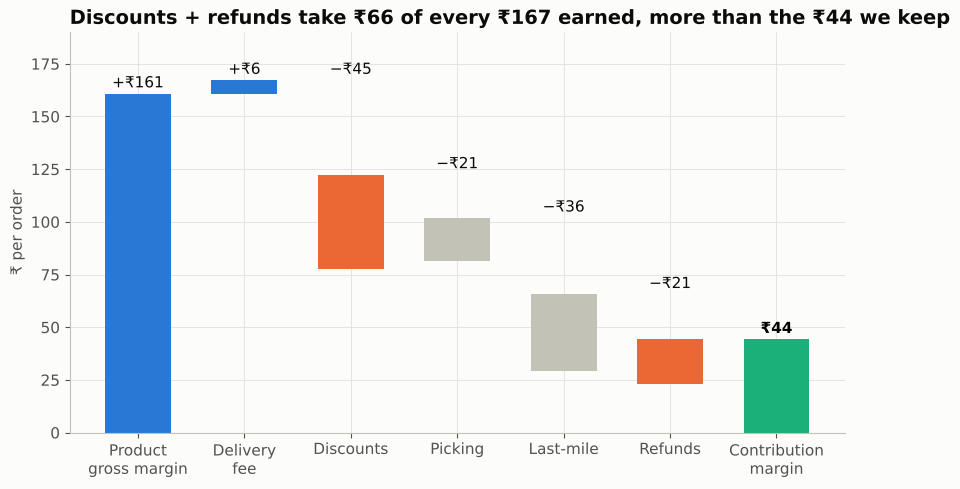

In [8]:
u = unit.iloc[0]
steps = [("Product\ngross margin", u.gross_margin), ("Delivery\nfee", u.delivery_fee), ("Discounts", u.discount),
         ("Picking", u.picking), ("Last-mile", u.last_mile), ("Refunds", u.refunds)]
fig, ax = plt.subplots(figsize=(10, 5.2))
run = 0
for i, (lab, v) in enumerate(steps):
    col = BLUE if v > 0 else (ORANGE if lab in ("Discounts", "Refunds") else GREY)
    ax.bar(i, v, bottom=run if v > 0 else run + v, color=col, width=0.62)
    ax.text(i, (run + v if v > 0 else run) + 3, f"{'+' if v>0 else '−'}₹{abs(v):.0f}", ha="center", color=INK, fontsize=11)
    run += v
ax.bar(len(steps), run, color=AQUA, width=0.62); ax.text(len(steps), run + 3, f"₹{run:.0f}", ha="center", fontweight="bold")
ax.set_xticks(range(len(steps) + 1), [s[0] for s in steps] + ["Contribution\nmargin"])
ax.set_ylabel("₹ per order"); ax.set_ylim(0, 190)
ax.set_title("Discounts + refunds take ₹66 of every ₹167 earned, more than the ₹44 we keep")
save(fig, "c1_unit_economics")

In [9]:
# Monthly trend: is the business getting healthier?
monthly = q("""
SELECT date_trunc('month', order_timestamp)::DATE AS month, COUNT(*) AS orders,
       AVG(contribution_margin_inr) AS cm_per_order, AVG(late_delivery_flag) AS late_rate,
       SUM(discount_inr)/SUM(basket_value_inr) AS discount_pct
FROM orders GROUP BY 1 ORDER BY 1
""")
monthly

,month,orders,cm_per_order,late_rate,discount_pct
0,2025-01-01,2505,44.409609,0.148807,0.079504
1,2025-02-01,2251,43.326242,0.139650,0.082515
2,2025-03-01,2547,45.507813,0.139793,0.079929
3,2025-04-01,2499,42.121425,0.182739,0.080380
4,2025-05-01,2520,45.027575,0.169675,0.078678
5,2025-06-01,2414,45.103993,0.216938,0.079168
6,2025-07-01,2476,45.957092,0.193154,0.079629
7,2025-08-01,2573,44.632767,0.204394,0.078789
8,2025-09-01,2531,41.334370,0.212495,0.081399
9,2025-10-01,2626,47.051954,0.151782,0.079637


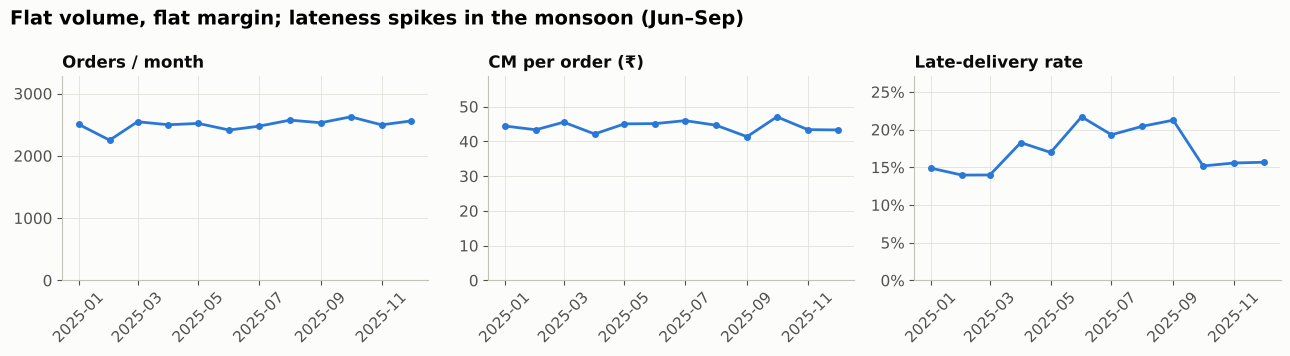

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, title, fmt in [(axs[0], "orders", "Orders / month", None), (axs[1], "cm_per_order", "CM per order (₹)", None),
                            (axs[2], "late_rate", "Late-delivery rate", "pct")]:
    ax.plot(monthly.month, monthly[col], color=BLUE, lw=2, marker="o", ms=4)
    ax.set_title(title, fontsize=12); ax.tick_params(axis="x", rotation=45)
    ax.set_ylim(0, monthly[col].max() * 1.25)
    if fmt: ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
fig.suptitle("Flat volume, flat margin; lateness spikes in the monsoon (Jun–Sep)", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout(); save(fig, "c2_monthly_trend")

I'd ask leadership to read the business off five numbers instead of order count:

1. Contribution margin per order: ₹44, or 7.9% of GMV. This is the north star. For reference, Blinkit turned EBITDA-positive in Q4 FY26 as its contribution margin rose from 3.9% to 5.4% of NOV.
2. Discounts as a share of GMV: 8.0%. In rupees that's about the same as all the contribution margin we made.
3. Refunds as a share of GMV: 3.8%. A quarter of orders get some refund, and 72% of loss-making orders have one.
4. Late deliveries: 17%, rising to 19–22% in the June–September monsoon. Cancellations (1%) aren't the issue.
5. Orders with at least one stock-out: 64%. This turns out to be the root of the refund problem (§4).

About one order in five loses money outright.

## 3 · What drives profitable repeat behaviour? (Ask 2)

In [11]:
# Customer-level features from the order table
cust = q("""
WITH o AS (
  SELECT customer_id, COUNT(*) n_orders, SUM(contribution_margin_inr) cm, SUM(basket_value_inr) gmv,
         SUM(discount_inr) disc, SUM(refund_inr) refund, AVG(unique_category_count) avg_categories
  FROM orders GROUP BY 1)
SELECT c.*, o.n_orders, o.cm, o.cm / o.n_orders AS cm_per_order, o.disc / o.gmv AS discount_share,
       o.avg_categories
FROM customers c LEFT JOIN o USING (customer_id)
""")

In [12]:
cust.head()

,customer_id,signup_date,acquisition_channel,city,city_tier,membership_status,first_order_offer_inr,historical_orders_12m,historical_margin_12m,days_since_last_order,app_sessions_30d,campaign_impressions_30d,campaign_clicks_30d,repeat_order_30d,n_orders,cm,cm_per_order,discount_share,avg_categories
0,C004264,2024-08-18,Paid Social,Tier2 D,Tier 2,Non-member,0,5,284.72,171,8,1,0,0,5,284.72,56.944000,0.083289,3.400000
1,C004158,2025-08-23,Paid Social,Metro B,Metro,Monthly member,75,6,434.60,53,1,0,0,0,6,434.60,72.433333,0.045799,4.000000
2,C000683,2024-06-21,Referral,Tier2 F,Tier 2,Non-member,50,8,491.30,87,21,5,1,0,8,491.30,61.412500,0.102565,3.250000
3,C005230,2025-04-11,Marketplace,Metro A,Metro,Non-member,150,5,161.77,68,10,14,2,0,5,161.77,32.354000,0.131429,3.000000
4,C007229,2025-01-28,Marketplace,Tier2 D,Tier 2,Non-member,100,6,321.61,9,12,7,4,1,6,321.61,53.601667,0.074711,4.333333


In [13]:
# Discount reliance vs. value: heavy discount users repeat as much but earn ~5x less
disc_rel = q("""
SELECT CASE WHEN discount_share <= 0.05 THEN '1. ≤5%' WHEN discount_share <= 0.08 THEN '2. 5–8%'
            WHEN discount_share <= 0.11 THEN '3. 8–11%' ELSE '4. >11%' END AS discount_share_of_basket,
       COUNT(*) customers, AVG(repeat_order_30d) repeat_30d, AVG(n_orders) orders_per_cust,
       AVG(cm_per_order) cm_per_order, AVG(cm) cm_per_customer
FROM cust WHERE n_orders > 0 GROUP BY 1 ORDER BY 1
""")
disc_rel

,discount_share_of_basket,customers,repeat_30d,orders_per_cust,cm_per_order,cm_per_customer
0,1. ≤5%,1730,0.231214,2.653757,74.081446,184.561162
1,2. 5–8%,2350,0.380426,4.285106,53.122787,222.438855
2,3. 8–11%,1883,0.432289,5.570898,37.192756,204.549347
3,4. >11%,796,0.433417,6.091709,14.738496,126.933505


In [14]:
# Order-level discount depth vs. contribution margin
disc_depth = q("""
SELECT NTILE(5) OVER (ORDER BY discount_inr / basket_value_inr) AS discount_quintile,
       discount_inr / basket_value_inr AS d, contribution_margin_inr, basket_value_inr FROM orders
""")

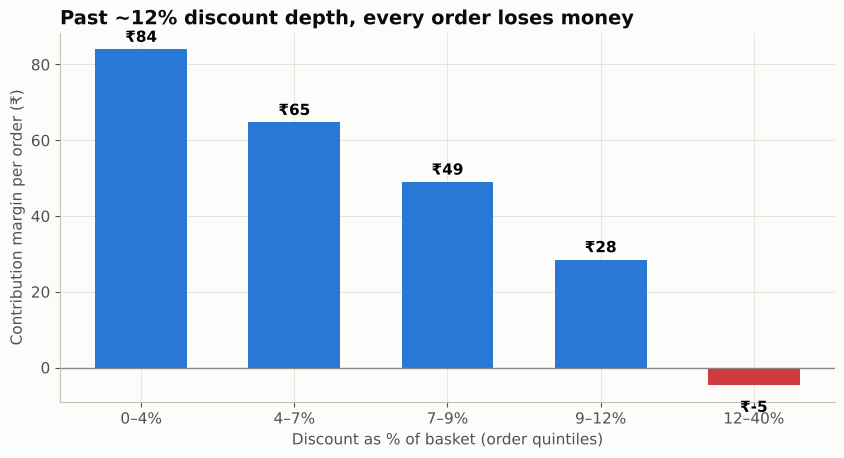

,discount_share_of_basket,customers,repeat_30d,orders_per_cust,cm_per_order,cm_per_customer
0,1. ≤5%,1730,0.231214,2.653757,74.081446,184.561162
1,2. 5–8%,2350,0.380426,4.285106,53.122787,222.438855
2,3. 8–11%,1883,0.432289,5.570898,37.192756,204.549347
3,4. >11%,796,0.433417,6.091709,14.738496,126.933505


In [15]:
dq = disc_depth.groupby("discount_quintile").agg(lo=("d","min"), hi=("d","max"), cm=("contribution_margin_inr","mean")).reset_index()
dq["label"] = [f"{a*100:.0f}–{b*100:.0f}%" for a, b in zip(dq.lo, dq.hi)]
fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.bar(dq.label, dq.cm, color=[BLUE]*4 + [RED], width=0.6)
for b, v in zip(bars, dq.cm): ax.text(b.get_x()+b.get_width()/2, v + (2 if v > 0 else -7), f"₹{v:.0f}", ha="center", fontweight="bold")
ax.axhline(0, color=MUTED, lw=1); ax.set_xlabel("Discount as % of basket (order quintiles)"); ax.set_ylabel("Contribution margin per order (₹)")
ax.set_title("Past ~12% discount depth, every order loses money")
save(fig, "c3_discount_depth")
disc_rel

In [16]:
# Engagement that matters vs. engagement that doesn't
engage = q("""
SELECT 'App sessions (30d)' AS signal,
       CASE WHEN app_sessions_30d <= 3 THEN '1. 0–3' WHEN app_sessions_30d <= 7 THEN '2. 4–7'
            WHEN app_sessions_30d <= 12 THEN '3. 8–12' ELSE '4. 13+' END AS bucket,
       COUNT(*) customers, AVG(repeat_order_30d) repeat_30d, AVG(historical_margin_12m) margin_12m
FROM customers GROUP BY 1,2
UNION ALL
SELECT 'Marketing clicks (30d)', CAST(campaign_clicks_30d AS VARCHAR), COUNT(*), AVG(repeat_order_30d), AVG(historical_margin_12m)
FROM customers GROUP BY 1,2
UNION ALL
SELECT 'First-order offer (₹)',
       CASE WHEN first_order_offer_inr = 0 THEN '1. none' WHEN first_order_offer_inr <= 75 THEN '2. ≤75'
            WHEN first_order_offer_inr <= 112 THEN '3. 76–112' ELSE '4. 113+' END,
       COUNT(*), AVG(repeat_order_30d), AVG(historical_margin_12m)
FROM customers GROUP BY 1,2
ORDER BY 1,2
""")
engage

,signal,bucket,customers,repeat_30d,margin_12m
0,App sessions (30d),1. 0–3,2013,0.104322,66.085142
1,App sessions (30d),2. 4–7,2127,0.210625,117.099939
2,App sessions (30d),3. 8–12,2074,0.339923,180.582430
3,App sessions (30d),4. 13+,1786,0.610302,320.044059
4,First-order offer (₹),1. none,2261,0.304732,163.113905
5,First-order offer (₹),2. ≤75,2272,0.299296,161.592152
6,First-order offer (₹),3. 76–112,2343,0.313700,168.053589
7,First-order offer (₹),4. 113+,1124,0.310498,176.637135
8,Marketing clicks (30d),0,2230,0.305381,164.189341
9,Marketing clicks (30d),1,1763,0.317640,161.680221


In [17]:
# Basket breadth, membership and acquisition channel
breadth = q("""
SELECT 'Avg categories / order' AS dim,
       CASE WHEN avg_categories <= 3 THEN '1. ≤3' WHEN avg_categories <= 5 THEN '2. 3–5' ELSE '3. >5' END AS bucket,
       COUNT(*) customers, AVG(repeat_order_30d) repeat_30d, AVG(cm_per_order) cm_per_order, AVG(discount_share) discount_share
FROM cust WHERE n_orders > 0 GROUP BY 1,2
UNION ALL
SELECT 'Membership', membership_status, COUNT(*), AVG(repeat_order_30d), AVG(cm_per_order), AVG(discount_share)
FROM cust WHERE n_orders > 0 GROUP BY 1,2
UNION ALL
SELECT 'Channel', acquisition_channel, COUNT(*), AVG(repeat_order_30d), AVG(cm_per_order), AVG(discount_share)
FROM cust WHERE n_orders > 0 GROUP BY 1,2
ORDER BY 1,2
""")
breadth

,dim,bucket,customers,repeat_30d,cm_per_order,discount_share
0,Avg categories / order,1. ≤3,1598,0.229662,56.138317,0.065004
1,Avg categories / order,2. 3–5,4448,0.427158,47.127166,0.075165
2,Avg categories / order,3. >5,713,0.260870,49.697879,0.067413
3,Channel,Affiliate,991,0.353179,50.460653,0.071561
4,Channel,Marketplace,999,0.382382,48.913435,0.071855
5,Channel,Organic,2018,0.375124,48.067629,0.073531
6,Channel,Paid Social,1720,0.350000,49.547365,0.071263
7,Channel,Referral,1031,0.351115,52.058471,0.070434
8,Membership,Annual member,1351,0.377498,52.901646,0.056821
9,Membership,Monthly member,1734,0.361015,50.625444,0.058249


In [18]:
# Are the busiest customers the least profitable? (the COO's hypothesis)
busy = q("""
SELECT NTILE(5) OVER (ORDER BY n_orders, customer_id) AS frequency_quintile, n_orders, cm,
       CASE WHEN cm < 0 THEN 1 ELSE 0 END AS loss_customer
FROM cust WHERE n_orders > 0
""")

In [19]:
busy.groupby("frequency_quintile").agg(avg_orders=("n_orders","mean"), cm_per_customer=("cm","mean"),
                                       share_loss_making=("loss_customer","mean")).round(2)

,avg_orders,cm_per_customer,share_loss_making
frequency_quintile,,,
1,1.04,59.00,0.15
2,2.19,114.51,0.10
3,3.45,177.68,0.06
4,5.38,261.63,0.05
5,10.14,369.88,0.07


Repeat buying goes with habit. Customers with 13+ app sessions a month repeat at 61%, against 10% for those with 0–3 sessions. Marketing clicks show no link at all: repeat stays around 30–32% whether someone clicked zero times or four. Broader baskets help too. Customers averaging 3–5 categories per order repeat at 43%, against 23% for narrow baskets. Members cost less to serve, with discounts at 5.7% of their basket against 8.4% for non-members, and they earn more per order.

Some growth looks good and isn't. Customers who rely on discounts (over 11% of basket) repeat as often as anyone (43%) but earn ₹15 per order, against ₹74 for light-discount customers. Bigger first-order offers don't buy repeat either; it sits at 30–31% whether the offer was ₹0 or ₹150, and acquisition channel makes no difference.

The COO suspected the busiest customers might be the least profitable. In this data it's the other way round. The most frequent fifth earns ₹370 per customer, and only 7% of them lose money, against 15% of one-order customers. The leak is discount depth and refunds, not frequency.

## 4 · Operational priorities: where the money leaks, and why (Ask 3)

In [20]:
# The delivery promise ignores distance
promise = q("""
SELECT CASE WHEN delivery_distance_km <= 1 THEN '0–1 km' WHEN delivery_distance_km <= 2 THEN '1–2 km'
            WHEN delivery_distance_km <= 3 THEN '2–3 km' WHEN delivery_distance_km <= 4 THEN '3–4 km' ELSE '4+ km' END AS distance,
       promised_minutes, COUNT(*) orders, AVG(late_delivery_flag) late_rate, AVG(rating) rating
FROM orders WHERE cancelled_flag = 0 GROUP BY 1,2 ORDER BY 1,2
""")

promised_minutes,20,25,30
distance,,,
0–1 km,14%,3%,0%
1–2 km,27%,7%,2%
2–3 km,39%,14%,3%
3–4 km,56%,27%,8%
4+ km,72%,47%,20%


promised_minutes,20,25,30
distance,,,
0–1 km,24%,25%,51%
1–2 km,25%,25%,50%
2–3 km,26%,25%,50%
3–4 km,24%,25%,51%
4+ km,24%,24%,51%


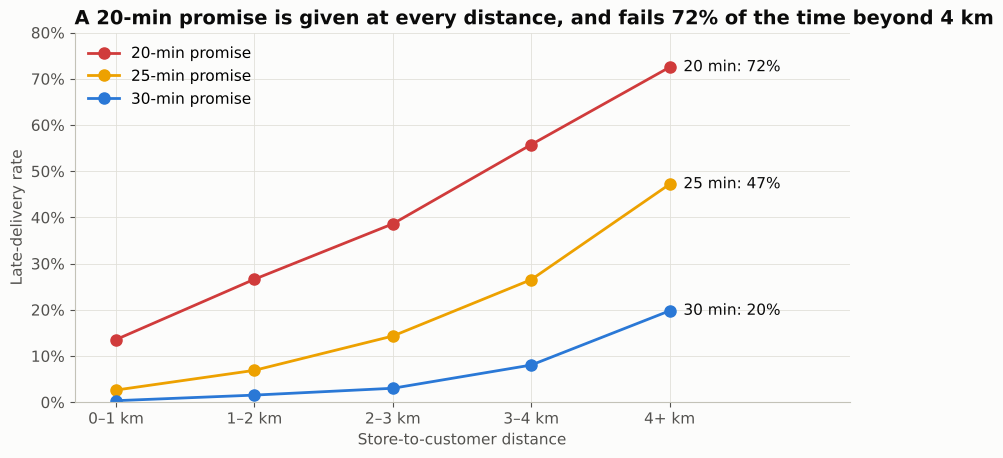

In [21]:
pv = promise.pivot(index="distance", columns="promised_minutes", values="late_rate")
mix = promise.pivot(index="distance", columns="promised_minutes", values="orders"); mix = mix.div(mix.sum(1), axis=0)
display(pv.style.format("{:.0%}").background_gradient(cmap="Oranges", axis=None)); display(mix.style.format("{:.0%}"))
fig, ax = plt.subplots(figsize=(10, 4.8))
for c_, col in zip([20, 25, 30], [RED, YELLOW, BLUE]):
    ax.plot(pv.index, pv[c_], marker="o", lw=2, color=col, ms=8, label=f"{c_}-min promise")
    ax.text(len(pv)-0.9, pv[c_].iloc[-1], f"{c_} min: {pv[c_].iloc[-1]:.0%}", color=INK, va="center", fontsize=11)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.set_ylim(0, 0.8); ax.set_xlim(-0.3, len(pv) + 0.3)
ax.set_ylabel("Late-delivery rate"); ax.set_xlabel("Store-to-customer distance"); ax.legend(frameon=False, loc="upper left")
ax.set_title("A 20-min promise is given at every distance, and fails 72% of the time beyond 4 km")
save(fig, "c4_promise_vs_distance")

In [22]:
# Peak hours × weather
pw = q("""
SELECT weather_flag, CASE WHEN peak_period_flag = 1 THEN 'Peak' ELSE 'Off-peak' END AS period,
       COUNT(*) orders, AVG(late_delivery_flag) late_rate, AVG(contribution_margin_inr) cm_per_order
FROM orders GROUP BY 1,2 ORDER BY 1,2
""")
pw

,weather_flag,period,orders,late_rate,cm_per_order
0,Heat,Off-peak,2156,0.153271,45.140343
1,Heat,Peak,1257,0.317191,33.438019
2,Normal,Off-peak,12738,0.068963,48.792285
3,Normal,Peak,7520,0.201263,41.459507
4,Rain,Off-peak,4036,0.241069,44.141623
5,Rain,Peak,2293,0.474658,33.766350


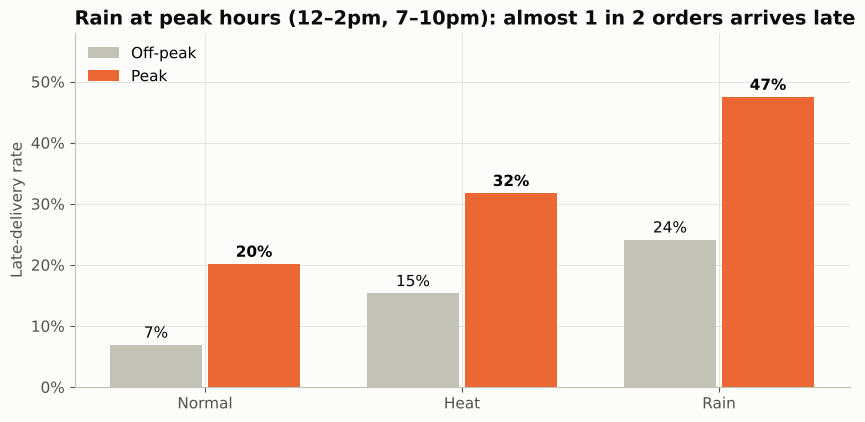

In [23]:
p = pw.pivot(index="weather_flag", columns="period", values="late_rate").loc[["Normal", "Heat", "Rain"]]
fig, ax = plt.subplots(figsize=(10, 4.6)); x = np.arange(len(p)); w = 0.36
for j, (per, col) in enumerate([("Off-peak", GREY), ("Peak", ORANGE)]):
    b = ax.bar(x + (j - .5) * w * 1.06, p[per], w, color=col, label=per)
    for bi, v in zip(b, p[per]): ax.text(bi.get_x() + bi.get_width()/2, v + .012, f"{v:.0%}", ha="center", fontweight="bold" if per=="Peak" else None)
ax.set_xticks(x, p.index); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.set_ylim(0, .58)
ax.legend(frameon=False); ax.set_ylabel("Late-delivery rate")
ax.set_title("Rain at peak hours (12–2pm, 7–10pm): almost 1 in 2 orders arrives late")
save(fig, "c6_peak_weather")

In [24]:
# Store league table: inventory accuracy, staffing and outcomes
stores_kpi = q("""
SELECT s.store_id, s.city, s.store_format, s.delivery_partner_model, s.inventory_accuracy_pct, s.staffing_fill_rate_pct,
       s.average_active_riders, COUNT(*) orders, AVG(o.contribution_margin_inr) cm_per_order,
       AVG(o.stockout_item_count) stockouts_per_order, AVG(o.refund_inr) refund_per_order,
       AVG(o.late_delivery_flag) late_rate, AVG(o.rating) rating
FROM orders o JOIN stores s USING (store_id)
GROUP BY ALL ORDER BY cm_per_order
""")
stores_kpi

,store_id,city,store_format,delivery_partner_model,inventory_accuracy_pct,staffing_fill_rate_pct,average_active_riders,orders,cm_per_order,stockouts_per_order,refund_per_order,late_rate,rating
0,S012,Tier2 D,Standard,Hybrid,88.8,76.9,16,860,33.317151,1.617442,29.386907,0.301775,3.862302
1,S011,Tier2 E,Small,Dedicated,84.5,76.5,17,829,35.202642,2.232811,27.162183,0.306943,3.565875
2,S027,Metro A,Standard,Hybrid,88.7,78.2,26,775,35.271897,1.643871,27.965613,0.237908,3.880562
3,S003,Tier2 D,Standard,Dedicated,89.5,69.8,37,797,38.726763,1.589711,25.185056,0.254777,3.932432
4,S008,Metro C,Large,Hybrid,90.9,96.2,22,839,39.061156,1.402861,22.003766,0.171875,4.031513
5,S016,Tier2 D,Standard,Dedicated,89.0,97.3,24,834,39.466894,1.629496,26.920012,0.136638,3.961625
6,S035,Metro B,Standard,Marketplace,90.0,97.0,41,830,39.598289,1.455422,23.745711,0.131227,4.061947
7,S007,Tier2 E,Large,Hybrid,91.1,83.1,30,856,39.627021,1.332944,23.220386,0.190813,4.116279
8,S026,Metro A,Standard,Hybrid,89.7,75.6,18,850,40.071765,1.500000,25.083765,0.247619,3.964730
9,S033,Metro A,Small,Hybrid,87.5,71.7,52,864,40.672755,1.802083,26.089028,0.174269,3.802151


                        cm_per_order  stockouts_per_order  refund_per_order  late_rate  rating  inventory_accuracy_pct  staffing_fill_rate_pct
inventory_accuracy_pct          0.77                -1.00             -0.88      -0.41    0.99                    1.00                    0.34
staffing_fill_rate_pct          0.27                -0.34             -0.29      -0.66    0.36                    0.34                    1.00
Each +1pp inventory accuracy ≈ +₹1.16 CM per order (store-level OLS, n=36)


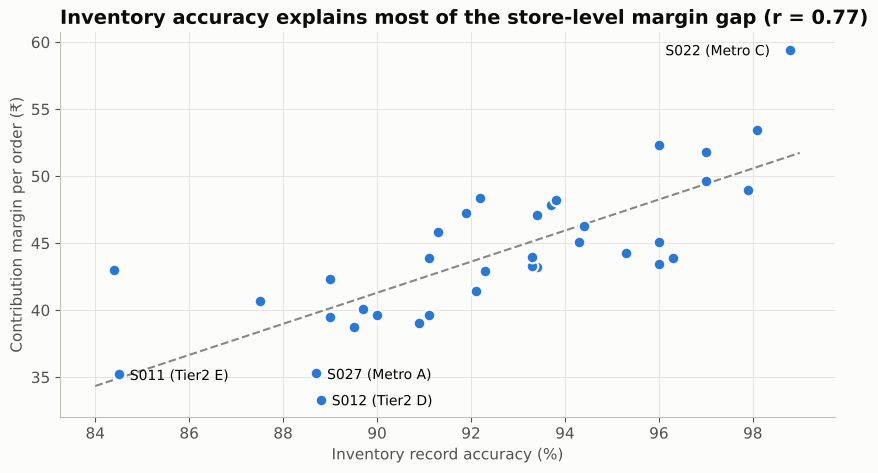

In [25]:
print(stores_kpi[["cm_per_order","stockouts_per_order","refund_per_order","late_rate","rating",
                  "inventory_accuracy_pct","staffing_fill_rate_pct"]].corr().loc[
      ["inventory_accuracy_pct","staffing_fill_rate_pct"]].round(2))
slope, icpt = np.polyfit(stores_kpi.inventory_accuracy_pct, stores_kpi.cm_per_order, 1)
print(f"Each +1pp inventory accuracy ≈ +₹{slope:.2f} CM per order (store-level OLS, n=36)")
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(stores_kpi.inventory_accuracy_pct, stores_kpi.cm_per_order, s=70, color=BLUE, edgecolor="#fcfcfb", lw=1.5, zorder=3)
xs = np.linspace(84, 99, 10); ax.plot(xs, icpt + slope * xs, color=MUTED, lw=1.5, ls="--")
for _, r in stores_kpi.nsmallest(3, "cm_per_order").iterrows():
    ax.annotate(f"{r.store_id} ({r.city})", (r.inventory_accuracy_pct, r.cm_per_order), xytext=(8, -4), textcoords="offset points", fontsize=10)
r = stores_kpi.nlargest(1, "cm_per_order").iloc[0]
ax.annotate(f"{r.store_id} ({r.city})", (r.inventory_accuracy_pct, r.cm_per_order), xytext=(-90, -4), textcoords="offset points", fontsize=10)
ax.set_xlabel("Inventory record accuracy (%)"); ax.set_ylabel("Contribution margin per order (₹)")
ax.set_title(f"Inventory accuracy explains most of the store-level margin gap (r = {np.corrcoef(stores_kpi.inventory_accuracy_pct, stores_kpi.cm_per_order)[0,1]:.2f})")
save(fig, "c5_store_inventory")

In [26]:
# The mechanism: stock-outs → refunds → margin and rating
so_mech = q("""
SELECT CASE WHEN stockout_item_count = 0 THEN '0' WHEN stockout_item_count = 1 THEN '1'
            WHEN stockout_item_count = 2 THEN '2' ELSE '3+' END AS stockout_items,
       COUNT(*) orders, AVG(refund_inr) refund_per_order, AVG(contribution_margin_inr) cm_per_order, AVG(rating) rating
FROM orders GROUP BY 1 ORDER BY 1
""")
so_mech

,stockout_items,orders,refund_per_order,cm_per_order,rating
0,0,10815,10.281355,56.572850,4.953626
1,1,9741,27.655703,39.313713,4.228860
2,2,5475,27.459180,35.942767,3.688801
3,3+,3969,27.423973,34.429506,2.944320


In [27]:
# Inventory-accuracy quartiles (store-level, order-weighted)
inv_q = q("""
SELECT q, MIN(inventory_accuracy_pct) lo, MAX(inventory_accuracy_pct) hi, COUNT(*) orders,
       AVG(stockout_item_count) stockouts, AVG(refund_inr) refund, AVG(contribution_margin_inr) cm_per_order, AVG(rating) rating
FROM (SELECT o.*, s.inventory_accuracy_pct, NTILE(4) OVER (ORDER BY s.inventory_accuracy_pct) q FROM orders o JOIN stores s USING (store_id))
GROUP BY q ORDER BY q
""")
inv_q

,q,lo,hi,orders,stockouts,refund,cm_per_order,rating
0,1,84.4,90.0,7500,1.765733,26.902087,38.405584,3.832719
1,2,90.0,93.3,7500,1.300667,21.872713,43.429451,4.126784
2,3,93.3,95.3,7500,0.966933,20.071664,45.478348,4.314655
3,4,95.3,98.8,7500,0.597333,16.456444,49.783632,4.559259


In [28]:
# Is lateness itself costly? Compare late vs on-time *within the same distance band*
late_cost = q("""
SELECT CASE WHEN delivery_distance_km <= 2 THEN '≤2 km' WHEN delivery_distance_km <= 4 THEN '2–4 km' ELSE '4+ km' END AS band,
       late_delivery_flag, COUNT(*) orders, AVG(contribution_margin_inr) cm, AVG(refund_inr) refund,
       AVG(rating) rating, AVG(service_contact_flag) contact_rate
FROM orders WHERE cancelled_flag = 0 GROUP BY 1,2 ORDER BY 1,2
""")
late_cost

,band,late_delivery_flag,orders,cm,refund,rating,contact_rate
0,2–4 km,0.0,12176,47.542190,17.504493,4.281833,0.110956
1,2–4 km,1.0,2830,40.387046,19.082739,3.905431,0.186219
2,4+ km,0.0,2300,38.598217,18.133117,4.277651,0.116957
3,4+ km,1.0,1485,35.966808,18.807077,3.811681,0.193939
4,≤2 km,0.0,10089,57.124889,17.571514,4.271483,0.109327
5,≤2 km,1.0,815,48.413239,17.823828,3.933333,0.184049


Where to act, and why:

| Priority | Evidence | Mechanism |
|---|---|---|
| Stores with inventory accuracy under ~90% (S011, S012, S027, S019 and others) | Store margin per order correlates 0.77 with inventory accuracy; stock-outs correlate almost −1.0 with it | Wrong stock records mean items are missing at picking, which leads to substitutions and refunds. Ratings fall from 4.95 with no stock-out to 2.94 with three or more |
| 20-minute promise on orders over 2 km | The promise mix is the same at every distance. 20-minute orders are late 39% of the time at 2–3 km and 72% beyond 4 km | The promise is chosen without looking at distance |
| Peak hours in rain or heat (12–2pm, 7–10pm) | 47% late in rain at peak, against 7% at normal off-peak times | Likely rider supply that doesn't flex with weather |
| Under-staffed stores (shift fill rate under 80%) | Staffing and late rate correlate −0.66 across stores | Picking queues delay dispatch |
| Orders over 4 km | ₹33 margin per order against ₹55 under 1 km, and 39% late | Last-mile cost rises about ₹5 per km |

Lateness costs money in its own right. Comparing orders in the same distance band, a late order earns ₹3–9 less, gets rated about 0.4 lower and leads to 1.7 times as many support contacts.

City tier, delivery-partner model and day of week barely move margin (±₹2), so this is a store operations problem rather than a geography one.

## 5 · Promotion strategy: who should get an offer? (Ask 4)
The Q1 campaign was randomized: 2,832 customers in control and 5,168 in treatment, split across three offer types. First I check that the randomization holds.

In [29]:
# Randomization balance check
bal = q("""
SELECT offer_type, COUNT(*) n, AVG(c.days_since_last_order) recency, AVG(c.app_sessions_30d) sessions,
       AVG(c.historical_orders_12m) orders_12m, AVG(c.historical_margin_12m) margin_12m,
       AVG(CASE WHEN c.membership_status <> 'Non-member' THEN 1 ELSE 0 END) member_share
FROM campaign_assignments a JOIN customers c USING (customer_id) GROUP BY 1 ORDER BY 1
""")
bal

,offer_type,n,recency,sessions,orders_12m,margin_12m,member_share
0,Fixed discount,1573,109.213605,8.216147,3.680865,164.769701,0.441195
1,Free delivery,1559,106.626684,8.152021,3.703656,167.004355,0.442591
2,No offer,2832,105.959040,8.284251,3.796610,166.673277,0.460805
3,Percentage discount,2036,105.343320,8.408153,3.774067,165.356758,0.461690


The groups look the same on recency, sessions, past orders, margin and membership, so differences in outcomes can be read as caused by the offer.

In [30]:
# Redemption vs. incrementality by offer
camp = q("""
WITH ctrl AS (SELECT AVG(post_campaign_orders) o0, AVG(post_campaign_margin_inr) m0 FROM campaign_assignments WHERE assignment_group='Control')
SELECT offer_type, COUNT(*) customers, AVG(offer_value_inr) offer_value, AVG(offer_redeemed_flag) redemption,
       AVG(post_campaign_orders) - (SELECT o0 FROM ctrl) AS incr_orders_per_cust,
       AVG(post_campaign_margin_inr) - (SELECT m0 FROM ctrl) AS incr_margin_per_cust
FROM campaign_assignments GROUP BY 1 ORDER BY incr_margin_per_cust DESC
""")
camp

,offer_type,customers,offer_value,redemption,incr_orders_per_cust,incr_margin_per_cust
0,No offer,2832,0.0,0.000000,0.000000,0.000000
1,Free delivery,1559,39.0,0.317511,0.160140,-2.096911
2,Percentage discount,2036,75.0,0.319745,0.143475,-14.074296
3,Fixed discount,1573,100.0,0.316592,0.174022,-20.644710


In [31]:
rng = np.random.default_rng(7)
kc = q("SELECT a.*, c.days_since_last_order, c.app_sessions_30d, c.membership_status FROM campaign_assignments a JOIN customers c USING (customer_id)")
kc["segment"] = np.where(kc.days_since_last_order > 90, "Lapsed >90d", "Active ≤90d") + " · " + \
                np.where(kc.app_sessions_30d <= 7, "low engagement", "high engagement")
def uplift(df, offer, y="post_campaign_margin_inr", B=2000):
    t = df.loc[df.offer_type == offer, y].to_numpy(); c = df.loc[df.offer_type == "No offer", y].to_numpy()
    boots = [rng.choice(t, len(t)).mean() - rng.choice(c, len(c)).mean() for _ in range(B)]
    return t.mean() - c.mean(), *np.percentile(boots, [2.5, 97.5])
rows = []
for off in ["Fixed discount", "Percentage discount", "Free delivery"]:
    rows.append(("All customers", off, *uplift(kc, off), kc[kc.offer_type == off].offer_redeemed_flag.mean(), (kc.offer_type == off).sum()))
    for seg, df in kc.groupby("segment"):
        rows.append((seg, off, *uplift(df, off), df[df.offer_type == off].offer_redeemed_flag.mean(), (df.offer_type == off).sum()))
upl = pd.DataFrame(rows, columns=["segment", "offer", "margin_uplift", "ci_low", "ci_high", "redemption", "n_treated"])
upl["significant"] = np.where(upl.ci_low > 0, "positive ✓", np.where(upl.ci_high < 0, "negative ✗", "not significant"))
upl.round(2)

,segment,offer,margin_uplift,ci_low,ci_high,redemption,n_treated,significant
0,All customers,Fixed discount,-20.64,-26.89,-14.74,0.32,1573,negative ✗
1,Active ≤90d · high engagement,Fixed discount,-39.26,-51.43,-26.28,0.41,539,negative ✗
2,Active ≤90d · low engagement,Fixed discount,-23.47,-34.91,-12.59,0.31,282,negative ✗
3,Lapsed >90d · high engagement,Fixed discount,-14.91,-30.03,0.13,0.31,224,not significant
4,Lapsed >90d · low engagement,Fixed discount,-1.71,-9.97,6.34,0.23,528,not significant
5,All customers,Percentage discount,-14.07,-19.56,-8.51,0.32,2036,negative ✗
6,Active ≤90d · high engagement,Percentage discount,-24.73,-36.71,-13.30,0.43,697,negative ✗
7,Active ≤90d · low engagement,Percentage discount,-13.11,-23.57,-3.01,0.26,414,negative ✗
8,Lapsed >90d · high engagement,Percentage discount,-19.50,-32.43,-6.50,0.30,294,negative ✗
9,Lapsed >90d · low engagement,Percentage discount,-1.36,-8.46,5.90,0.25,631,not significant


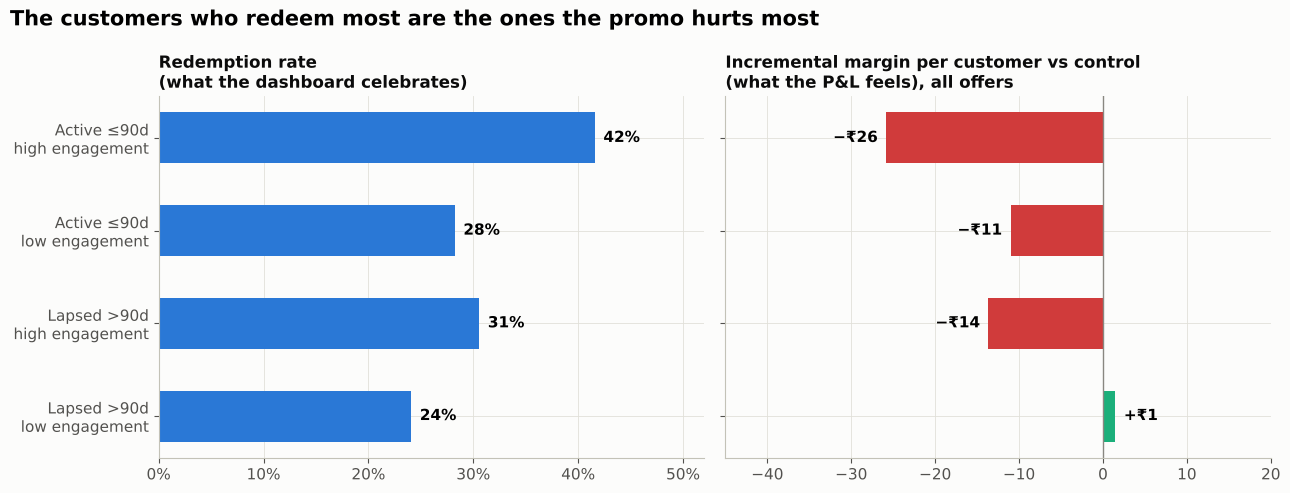

In [32]:
# The money chart: redemption rewards the wrong customers
seg_order = ["Active ≤90d · high engagement", "Active ≤90d · low engagement", "Lapsed >90d · high engagement", "Lapsed >90d · low engagement"]
red = kc[kc.assignment_group == "Treatment"].groupby("segment").offer_redeemed_flag.mean().reindex(seg_order)
blend = []
for seg in seg_order:
    d = kc[kc.segment == seg]
    blend.append(d[d.assignment_group == "Treatment"].post_campaign_margin_inr.mean() - d[d.assignment_group == "Control"].post_campaign_margin_inr.mean())
fd = upl[(upl.offer == "Free delivery") & (upl.segment.isin(seg_order))].set_index("segment").reindex(seg_order)
labels = [s.replace(" · ", "\n") for s in seg_order]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
a1.barh(labels, red, color=BLUE, height=0.55); a1.invert_yaxis(); a1.xaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
for i, v in enumerate(red): a1.text(v + .008, i, f"{v:.0%}", va="center", fontweight="bold")
a1.set_xlim(0, .52); a1.set_title("Redemption rate\n(what the dashboard celebrates)", fontsize=12)
cols = [RED if v < 0 else AQUA for v in blend]
a2.barh(labels, blend, color=cols, height=0.55); a2.invert_yaxis(); a2.axvline(0, color=MUTED, lw=1)
for i, v in enumerate(blend): a2.text(v + (1 if v >= 0 else -1), i, f"{'+' if v>=0 else '−'}₹{abs(v):.0f}", va="center", ha="left" if v >= 0 else "right", fontweight="bold")
a2.set_xlim(-45, 20); a2.set_yticklabels([]); a2.set_title("Incremental margin per customer vs control\n(what the P&L feels), all offers", fontsize=12)
fig.suptitle("The customers who redeem most are the ones the promo hurts most", x=0.01, ha="left", fontweight="bold", fontsize=15)
fig.tight_layout(); save(fig, "c7_redemption_vs_uplift")

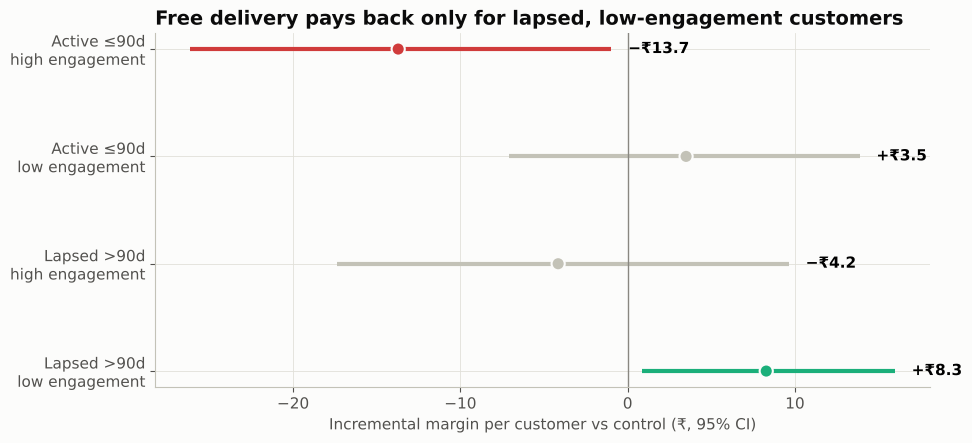

In [33]:
# Free delivery by segment, with 95% bootstrap CIs
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(fd)); colors = [AQUA if l > 0 else (RED if h < 0 else GREY) for l, h in zip(fd.ci_low, fd.ci_high)]
ax.hlines(y, fd.ci_low, fd.ci_high, color=colors, lw=3); ax.scatter(fd.margin_uplift, y, color=colors, s=90, zorder=3, edgecolor="#fcfcfb", lw=1.5)
for i, (m, h) in enumerate(zip(fd.margin_uplift, fd.ci_high)): ax.text(h + 1, i, f"{'+' if m>=0 else '−'}₹{abs(m):.1f}", va="center", fontweight="bold")
ax.axvline(0, color=MUTED, lw=1); ax.set_yticks(y, labels); ax.invert_yaxis()
ax.set_xlabel("Incremental margin per customer vs control (₹, 95% CI)")
ax.set_title("Free delivery pays back only for lapsed, low-engagement customers")
save(fig, "c8_free_delivery_ci")

Holdout check: pick the best rule on one random half of customers and see if it holds on the other half, so I'm not cherry-picking a noisy segment.

In [34]:
kc["half"] = np.random.default_rng(2026).random(len(kc)) < 0.5
def best_cell(df):
    out = []
    for seg, d in df.groupby("segment"):
        c0 = d[d.offer_type == "No offer"].post_campaign_margin_inr.mean()
        for off in ["Fixed discount", "Percentage discount", "Free delivery"]:
            out.append((seg, off, d[d.offer_type == off].post_campaign_margin_inr.mean() - c0))
    return pd.DataFrame(out, columns=["segment", "offer", "uplift"]).sort_values("uplift", ascending=False)
train_pick = best_cell(kc[kc.half]).head(3); test_eval = best_cell(kc[~kc.half])
print("Top cells chosen on TRAIN half:\n", train_pick.round(1).to_string(index=False))
chosen = train_pick.iloc[0]
print(f"\nSame cell on TEST half: ₹{test_eval.set_index(['segment','offer']).loc[(chosen.segment, chosen.offer), 'uplift']:.1f} per customer")

Top cells chosen on TRAIN half:
                      segment               offer  uplift
Lapsed >90d · low engagement       Free delivery     5.2
Active ≤90d · low engagement       Free delivery     1.7
Lapsed >90d · low engagement Percentage discount    -2.4

Same cell on TEST half: ₹11.2 per customer


In [35]:
# Policy value per 10,000 customers: blanket (as run) vs targeted
seg_share = (kc.segment == "Lapsed >90d · low engagement").mean()
blanket = kc[kc.assignment_group == "Treatment"].post_campaign_margin_inr.mean() - kc[kc.assignment_group == "Control"].post_campaign_margin_inr.mean()
target_uplift = fd.loc["Lapsed >90d · low engagement", "margin_uplift"]
target_orders = uplift(kc[kc.segment == "Lapsed >90d · low engagement"], "Free delivery", y="post_campaign_orders")[0]
policy = pd.DataFrame({
    "policy": ["Blanket (as run): offers to everyone", "Targeted: free delivery to lapsed + low-engagement only"],
    "customers_contacted_per_10k": [10000, round(10000 * seg_share)],
    "incremental_margin_per_10k_inr": [blanket * 10000, target_uplift * 10000 * seg_share],
})
print(f"Target segment = {seg_share:.0%} of base; +{target_orders:.2f} incremental orders per targeted customer")
policy.round(0)

Target segment = 33% of base; +0.28 incremental orders per targeted customer


,policy,customers_contacted_per_10k,incremental_margin_per_10k_inr
0,Blanket (as run): offers to everyone,10000,-124610.0
1,Targeted: free delivery to lapsed + low-engage...,3258,26985.0


What the campaign tells us:

- As run, it lost money. Treated customers produced ₹12.5 less margin each than control. A fixed ₹100 off was the worst at −₹21 (95% CI −27 to −15), percentage off came in at −₹14, and free delivery at −₹2, which isn't significant.
- Redemption pointed the wrong way. Active, highly engaged customers redeemed most often (42%) and produced the worst result: −₹26 across all offers and −₹39 on the fixed discount. They were buying anyway, so the discount just paid for orders we'd have had.
- One group is worth a promo: customers lapsed more than 90 days with 7 or fewer app sessions, given free delivery. That's +₹8.3 per customer (CI +₹1 to +₹16) and +0.28 extra orders each. A rule picked on one random half of customers (+₹5) held on the other half (+₹11).
- Active, engaged customers shouldn't get one. Service quality is a better lever for them.
- Both targeting fields, `days_since_last_order` and `app_sessions_30d`, are known before the campaign, so the rule doesn't leak outcome data.

## 6 · Recommendations: three actions for next quarter (Ask 5)

In [36]:
# R2 sizing: distance-aware promise. Assign promise by distance using observed late rates.
o = q("SELECT * FROM orders WHERE cancelled_flag = 0")
o["dband"] = pd.cut(o.delivery_distance_km, [-0.1, 1, 2, 3, 4, 99], labels=["0–1", "1–2", "2–3", "3–4", "4+"])
cell = o.groupby(["dband", "promised_minutes"]).late_delivery_flag.mean()
new_promise = {"0–1": 20, "1–2": 25, "2–3": 25, "3–4": 30, "4+": 30}
o["new_late"] = [cell[(b, new_promise[b])] for b in o.dband]
cur, new = o.late_delivery_flag.mean(), o.new_late.mean()
print(f"Late rate today {cur:.1%} → with distance-aware promise {new:.1%}  ({(cur-new)/cur:.0%} fewer late orders)")
share_fast = (o.dband.map(new_promise) <= 25).mean()
print(f"Orders still shown a ≤25-min promise: {share_fast:.0%} (today {(o.promised_minutes<=25).mean():.0%})")

Late rate today 17.3% → with distance-aware promise 11.8%  (32% fewer late orders)
Orders still shown a ≤25-min promise: 66% (today 50%)


In [37]:
# R3 sizing: lift bottom-quartile stores (inventory accuracy ≤ ~90%) to the median quartile's stock-out economics
gap = inv_q.loc[inv_q.q == 3, "cm_per_order"].iloc[0] - inv_q.loc[inv_q.q == 1, "cm_per_order"].iloc[0]
q1_orders = inv_q.loc[inv_q.q == 1, "orders"].iloc[0]
total_cm = kpi.contribution_margin_inr.iloc[0]
print(f"Bottom-quartile stores: {q1_orders:,} orders, ₹{gap:.1f}/order below Q3 stores")
print(f"Closing that gap = +₹{gap*q1_orders:,.0f} = +{gap*q1_orders/total_cm:.1%} of total contribution margin")

# R1 sizing on the same base: stopping blanket discounts
print(f"R1: moving from blanket to targeted promo swings margin by ₹{(target_uplift*seg_share - blanket)*10000:,.0f} per 10k customers")

Bottom-quartile stores: 7,500 orders, ₹7.1/order below Q3 stores
Closing that gap = +₹53,046 = +4.0% of total contribution margin
R1: moving from blanket to targeted promo swings margin by ₹151,595 per 10k customers


| # | Action | Target group | Expected effect | Main trade-off | How to test it first |
|---|---|---|---|---|---|
| 1 | Stop blanket discounts. Send free delivery only to lapsed, low-engagement customers, and cap any order discount at about 10% of basket | About a third of the base: 90+ days since last order, 7 or fewer app sessions | Per 10,000 customers the promo goes from −₹1.25 lakh to +₹0.27 lakh, with 67% fewer offers sent; +0.28 orders per targeted customer | Fewer redemptions and lower headline volume; some active users will notice the missing offer | Rerun the randomized test on the new rule with a 20% holdout for 4 weeks, judged on incremental margin rather than redemption |
| 2 | Make the delivery promise depend on distance: 20 minutes within 1 km, 25 up to 3 km, 30 beyond, with an extra 5 minutes and rider incentives in rain at peak | All orders, especially 2+ km and rainy peak slots | Late rate falls from 17.3% to about 11.8%, and more orders (66% vs 50%) still see a promise of 25 minutes or less | Longer ETAs for far-away customers could cut conversion, which this data can't show | Switchback test by store and hour for 3 weeks, tracking conversion, late rate, ratings and support contacts |
| 3 | Fix inventory accuracy in the bottom-quartile stores (≤90%) with cycle counts, scanner-based put-away and earlier stock-out warnings in the app | The bottom quarter of stores, all at or below 90% accuracy (S011, S012, S027, S019, S033 and others) | Close the ₹7/order gap to third-quartile stores, about +4% of total contribution margin; refunds down about ₹7 per order; ratings from 3.8 toward 4.3 | Staff time for daily cycle counts | Pilot in 4 stores against 4 matched control stores for 6 weeks (difference-in-differences), tracking stock-outs, refunds and margin per order |

Outside the case data:
- In January 2026 Blinkit and Zepto dropped their "10-minute" delivery claims after the Union Labour Minister raised rider safety (Outlook Business, The Week). A promise riders can't keep is now a reputational and regulatory risk as well as a service one.
- In Q4 FY26 Blinkit was EBITDA-positive as its contribution margin rose to 5.4% of NOV. Datum Intelligence estimates Instamart's discounts at about 28% of GOV in the same quarter, with Instamart still loss-making. Both point the same way as this case: discount spend has to earn its keep.

## 7 · QA: re-computing the headline numbers in pandas, without SQL

In [38]:
O, C, K = sheets["orders"], sheets["customers"], sheets["campaign_assignments"]
checks = {
    "CM per order": (O.contribution_margin_inr.mean(), kpi.cm_per_order.iloc[0]),
    "Discount % GMV": (O.discount_inr.sum() / O.basket_value_inr.sum(), kpi.discount_pct_gmv.iloc[0]),
    "Late rate": (O.late_delivery_flag.mean(), kpi.late_rate.iloc[0]),
    "Campaign margin uplift": (K[K.assignment_group=="Treatment"].post_campaign_margin_inr.mean() - K[K.assignment_group=="Control"].post_campaign_margin_inr.mean(), blanket),
}
qa_tbl = pd.DataFrame(checks, index=["pandas", "SQL"]).T; qa_tbl["match"] = np.isclose(qa_tbl.pandas, qa_tbl.SQL)
assert qa_tbl.match.all(); qa_tbl

,pandas,SQL,match
CM per order,44.274254,44.274254,True
Discount % GMV,0.080014,0.080014,True
Late rate,0.172756,0.172756,True
Campaign margin uplift,-12.461006,-12.461006,True


In [39]:
# Export tidy aggregate tables (for Tableau / Power BI if you want to rebuild the dashboard there)
OUT = "../exports" if os.path.isdir("../notebooks") or os.path.basename(os.getcwd()) == "notebooks" else "exports"
os.makedirs(OUT, exist_ok=True)
monthly.to_csv(f"{OUT}/monthly.csv", index=False); stores_kpi.to_csv(f"{OUT}/stores.csv", index=False)
upl.to_csv(f"{OUT}/campaign_uplift.csv", index=False); promise.to_csv(f"{OUT}/promise_distance.csv", index=False)
pw.to_csv(f"{OUT}/peak_weather.csv", index=False); kpi.to_csv(f"{OUT}/kpi.csv", index=False)
print("exported to", OUT)

exported to ../exports
